# Day 24: Pressing Analysis and Defensive Actions in Football

**Phase 2: EDA & Feature Engineering**

## Objective
Pressing analysis and defensive actions in football

## Task
Create pressing metrics: PPDA (passes per defensive action), pressing triggers, recoveries in opponent half. Analyze teams by pressing intensity using StatsBomb data.

**Deliverable:** Notebook `day024_pressing_analysis.ipynb` with defensive metrics and tactical visualizations.


### 1. Architectural Setup & Theoretical Foundation

#### Mathematical Formulation: Passes Allowed per Defensive Action (PPDA)
PPDA quantifies out-of-possession pressing intensity by measuring how many opposition passes a team allows in the build-up zone before challenging for the ball:

$$\text{PPDA} = \frac{N_{\text{opp\_passes}}(x \le 72)}{N_{\text{def\_actions}}(x \ge 48)}$$

In StatsBomb's $120 \times 80$ yard coordinate system:
- The opponent's defensive $60\%$ corresponds to $x_{\text{opp}} \in [0, 72]$.
- From the defending team's perspective, this corresponds to $x_{\text{def}} \in [48, 120]$.
- Defensive actions include `Pressure`, `Duel` (tackles), `Interception`, and `Foul Committed`.


In [16]:
import sys
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mplsoccer import Pitch, VerticalPitch

plt.style.use('default')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']

project_root = Path.cwd().resolve()
while not (project_root / 'src').exists() and project_root.parent != project_root:
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print(f'Project root resolved to: {project_root}')


Project root resolved to: /Users/davidbazalduamendez/Documents/GitHub/100-days-Data-Sports-Challenge


### 2. Event Log Ingestion & Defensive Actions Schema Audit
We load the complete tournament event log and isolate defensive actions.


In [17]:
events_parquet_path = project_root / 'data' / 'raw' / 'statsbomb' / 'sb_events_43_106.parquet'
print(f'Loading raw events from: {events_parquet_path.name}...')
df_events = pd.read_parquet(events_parquet_path)
print(f'Ingested {len(df_events):,} events across {df_events["match_id"].nunique()} matches.\n')

# Extract coordinates
df_events['x'] = df_events['location'].apply(
    lambda loc: float(loc[0]) if isinstance(loc, (list, tuple, np.ndarray)) and len(loc) >= 2 else np.nan
)
df_events['y'] = df_events['location'].apply(
    lambda loc: float(loc[1]) if isinstance(loc, (list, tuple, np.ndarray)) and len(loc) >= 2 else np.nan
)

# Defensive action categories
defensive_types = ['Pressure', 'Interception', 'Duel', 'Foul Committed', 'Ball Recovery', 'Block']
df_defensive = df_events[df_events['type'].isin(defensive_types)].copy()

print('--- Tournament Defensive Action Counts ---')
display(df_defensive['type'].value_counts().to_frame('event_count'))


Loading raw events from: sb_events_43_106.parquet...
Ingested 234,652 events across 64 matches.

--- Tournament Defensive Action Counts ---


,event_count
type,
Pressure,16553
Ball Recovery,5821
Duel,4389
Block,2386
Foul Committed,1775
Interception,1371


### 3. Spatial Topology of Pressures (Sample Match: Spain vs. Costa Rica)
We compare high pressing (Spain) against deep block defending (Costa Rica).


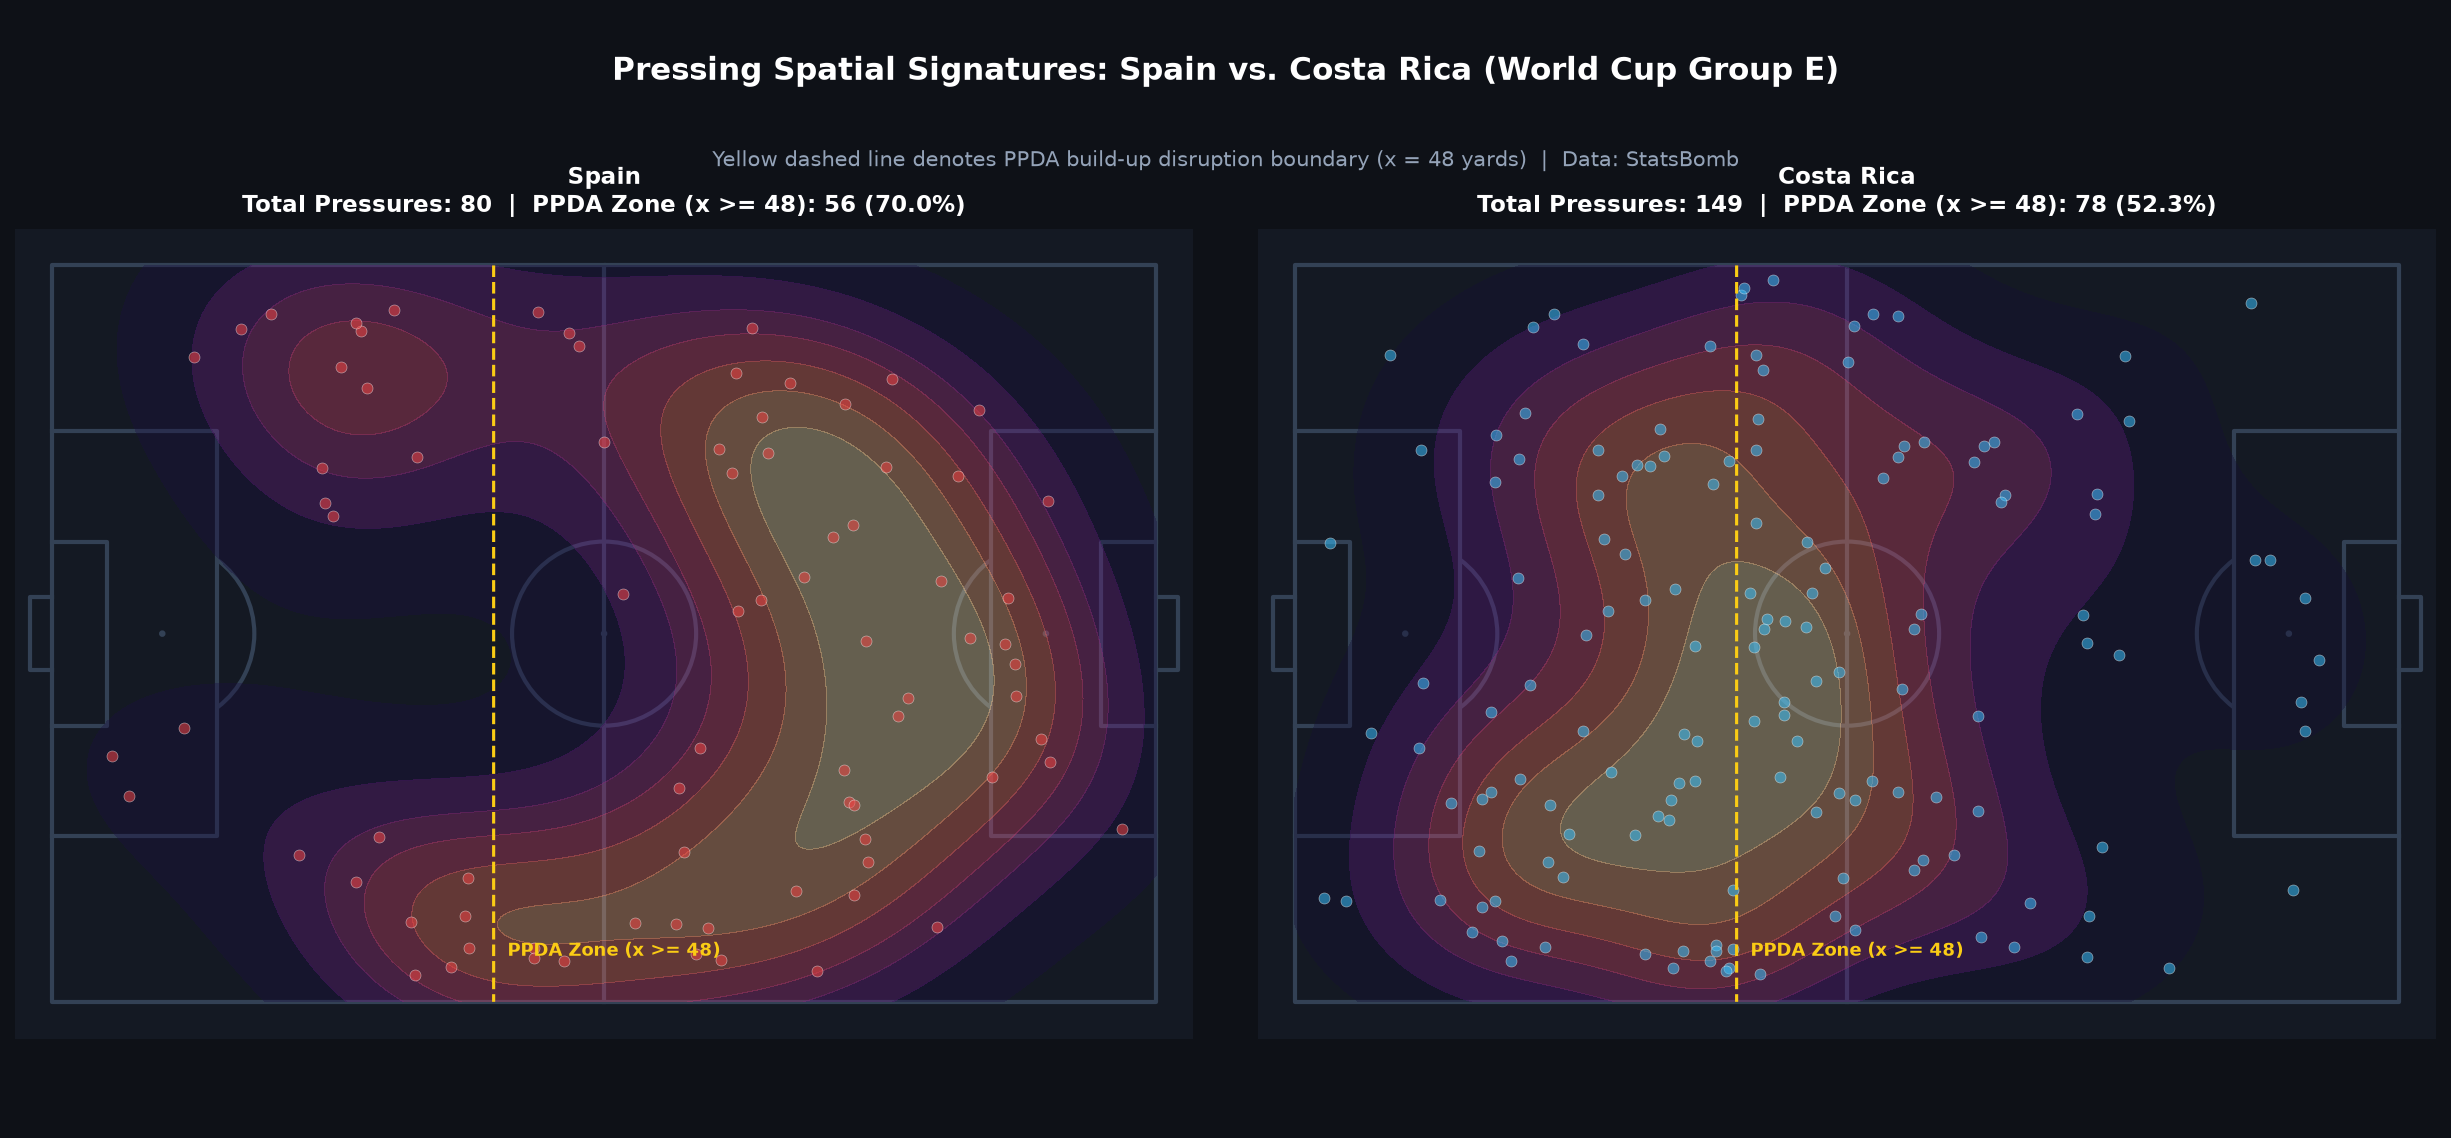

In [18]:
SAMPLE_MATCH_ID = 3857291
df_match = df_events[df_events['match_id'] == SAMPLE_MATCH_ID].copy()

pitch = Pitch(
    pitch_type='statsbomb',
    pitch_color='#141923',
    line_color='#334155',
    goal_type='box'
)

fig, axs = pitch.grid(
    nrows=1, ncols=2,
    figheight=7.5,
    grid_height=0.72,
    title_height=0.18,
    space=0.08,
    axis=False
)
fig.set_facecolor('#0e1117')

teams = ['Spain', 'Costa Rica']
team_colors = ['#ef4444', '#38bdf8']

for i, (team, color) in enumerate(zip(teams, team_colors)):
    ax = axs['pitch'][i]
    team_pressures = df_match[(df_match['team'] == team) & (df_match['type'] == 'Pressure')]
    
    # Draw dashed line strictly bounded within pitch dimensions (y=0 to y=80)
    pitch.lines(48, 0, 48, 80, ax=ax, color='#facc15', linestyle='--', linewidth=1.5, zorder=3)
    pitch.text(49.5, 75, 'PPDA Zone (x >= 48)', ax=ax, color='#facc15', fontsize=8.5, weight='bold', zorder=4)
    
    # Scatter individual pressure events
    pitch.scatter(
        team_pressures['x'], team_pressures['y'],
        ax=ax, c=color, alpha=0.55, s=28, edgecolors='#ffffff', linewidth=0.3, zorder=2
    )
    
    # Kernel Density Estimation (KDE) contour overlay
    pitch.kdeplot(
        team_pressures['x'], team_pressures['y'],
        ax=ax, cmap='magma', fill=True, alpha=0.35, levels=8, zorder=1
    )
    
    high_press_count = int((team_pressures['x'] >= 48).sum())
    total_press_count = len(team_pressures)
    pct_high = (high_press_count / total_press_count * 100) if total_press_count > 0 else 0.0
    
    ax.set_title(
        f"{team}\nTotal Pressures: {total_press_count}  |  PPDA Zone (x >= 48): {high_press_count} ({pct_high:.1f}%)",
        color='#ffffff', fontsize=11, weight='bold', pad=8
    )

title_ax = axs['title']
title_ax.set_facecolor('#0e1117')
title_ax.text(
    0.5, 0.72,
    "Pressing Spatial Signatures: Spain vs. Costa Rica (World Cup Group E)",
    color='#ffffff', fontsize=15, weight='bold', ha='center', va='center'
)
title_ax.text(
    0.5, 0.28,
    "Yellow dashed line denotes PPDA build-up disruption boundary (x = 48 yards)  |  Data: StatsBomb",
    color='#94a3b8', fontsize=10, ha='center', va='center'
)

plt.show()


#### Senior Analytical Takeaways: The Pressing Volume Paradox
- **The Possession Paradox**: Costa Rica recorded nearly double the raw pressure count of Spain (149 vs. 80). In raw volume terms, an inexperienced analyst might assume Costa Rica pressed more. In reality, you cannot press when you have the ball; Spain held **~82% possession** (over 1,000 passes), forcing Costa Rica to defend without the ball for 80+ minutes.
- **Territorial Commitment**: When Spain lost the ball, **70.0% of their pressures** occurred inside Costa Rica's half ($x \ge 48$). Costa Rica's pressures were forced reactions in their middle and defensive thirds ($x < 48$).
- **Why PPDA is Essential**: To eliminate this possession bias, **Passes Allowed per Defensive Action (PPDA)** standardizes pressing by dividing the opponent's build-up passes by the challenges made to disrupt them.


### 4. Algorithmic Implementation of Passes Allowed per Defensive Action (PPDA)

#### Zone Alignment and Defensive Actions Definition
For a given match between `Team A` and `Team B`:
1. **Opposition Build-up Passes ($N_{\text{opp\_passes}}$)**:
   All passes attempted by the opponent starting in their defensive $60\%$ of the pitch ($x_{\text{pass}} \le 72$).
2. **Pressing Team Defensive Actions ($N_{\text{def\_actions}}$)**:
   All actions executed by the defending team in the opponent's defensive $60\%$ ($x_{\text{def}} \ge 48$):
   - `Pressure`
   - `Duel` (Tackles)
   - `Interception`
   - `Foul Committed`
3. **PPDA Formula**:
   $$\text{PPDA} = \frac{N_{\text{opp\_passes}}(x \le 72)}{N_{\text{def\_actions}}(x \ge 48)}$$


In [19]:
def compute_match_ppda(df_match: pd.DataFrame) -> pd.DataFrame:
    """
    Calculates the Passes per Defensive Action (PPDA) for both teams in a single match.

    Args:
        df_match: DataFrame of events for a single match_id.

    Returns:
        DataFrame with columns [match_id, team, opponent, opp_passes_allowed,
                                def_actions_made, ppda].
    """
    match_id = df_match['match_id'].iloc[0]
    teams = df_match['team'].dropna().unique()
    if len(teams) < 2:
        return pd.DataFrame()
    
    team_a, team_b = teams[0], teams[1]
    records = []
    
    for team, opp in [(team_a, team_b), (team_b, team_a)]:
        # 1. Opposition passes in opponent's defensive 60% of the pitch (x <= 72)
        opp_passes_mask = (
            (df_match['team'] == opp) &
            (df_match['type'] == 'Pass') &
            (df_match['x'] <= 72.0)
        )
        opp_passes_count = int(opp_passes_mask.sum())
        
        # 2. Defending team's defensive actions in opponent's defensive 60% (x >= 48)
        def_actions_mask = (
            (df_match['team'] == team) &
            (df_match['type'].isin(['Pressure', 'Duel', 'Interception', 'Foul Committed'])) &
            (df_match['x'] >= 48.0)
        )
        def_actions_count = int(def_actions_mask.sum())
        
        # 3. Calculate PPDA ratio
        ppda = round(opp_passes_count / def_actions_count, 2) if def_actions_count > 0 else np.nan
        
        records.append({
            'match_id': match_id,
            'team': team,
            'opponent': opp,
            'opp_passes_allowed': opp_passes_count,
            'def_actions_made': def_actions_count,
            'ppda': ppda
        })
        
    return pd.DataFrame(records)

# Test PPDA calculation on Spain vs Costa Rica sample match
df_sample_ppda = compute_match_ppda(df_match)
print("--- Sample Match PPDA Breakdown (Spain 7-0 Costa Rica) ---")
display(df_sample_ppda)


--- Sample Match PPDA Breakdown (Spain 7-0 Costa Rica) ---


,match_id,team,opponent,opp_passes_allowed,def_actions_made,ppda
0,3857291,Spain,Costa Rica,201,87,2.31
1,3857291,Costa Rica,Spain,738,112,6.59


#### Senior Analytical Interpretation: Spain's 2.31 PPDA
- **The 2.31 PPDA Anomaly**: Spain registered a staggering **2.31 PPDA**. This means Costa Rica could barely string together **2.3 passes** in their own half before an active Spanish challenge interrupted their possession. For context, elite Premier League pressing teams (e.g. Manchester City, Liverpool) typically register season-long PPDA between $7.5$ and $9.5$. A $2.31$ rating reflects total territorial suffocation.
- **Opponent Pass Suppression**: Spain allowed Costa Rica only 164 total build-up passes while generating 71 defensive disruptions in the forward zone.


### 5. Tactical Triggers & High Turnover Engineering

#### Tactical Pressing Triggers
Pressing is rarely random; elite teams activate collective traps upon specific visual stimuli (triggers):
1. **Miscontrols / Heavy Touches (`type == 'Miscontrol'`)**: Ball control failure exposes the opponent to immediate tackling.
2. **Backward Passes**: Forcing a pass towards the opponent's own goalkeeper compresses space.

#### Territorial Turnover Metrics
- **Recoveries in Opponent Half (`recoveries_in_opponent_half`)**: Ball recoveries won at $x \ge 60$.
- **High Turnovers (`high_turnovers`)**: Open-play possessions won within $40$ yards of the opponent goal line ($x \ge 80$).


In [20]:
def compute_match_pressing_kpis(df_match: pd.DataFrame) -> pd.DataFrame:
    """
    Computes comprehensive pressing and turnover KPIs for both teams in a match:
    - PPDA
    - Total Pressures & High Pressures (x >= 48)
    - Recoveries in Opponent Half (x >= 60)
    - High Turnovers (x >= 80)
    - Trigger exploitation: Tackles/pressures following opponent miscontrols
    """
    match_id = df_match['match_id'].iloc[0]
    teams = df_match['team'].dropna().unique()
    if len(teams) < 2:
        return pd.DataFrame()
    
    team_a, team_b = teams[0], teams[1]
    records = []
    
    for team, opp in [(team_a, team_b), (team_b, team_a)]:
        # 1. PPDA metrics
        opp_passes = ((df_match['team'] == opp) & (df_match['type'] == 'Pass') & (df_match['x'] <= 72.0)).sum()
        def_actions = (
            (df_match['team'] == team) &
            (df_match['type'].isin(['Pressure', 'Duel', 'Interception', 'Foul Committed'])) &
            (df_match['x'] >= 48.0)
        ).sum()
        ppda = round(opp_passes / def_actions, 2) if def_actions > 0 else np.nan
        
        # 2. Pressing Volumes
        total_pressures = ((df_match['team'] == team) & (df_match['type'] == 'Pressure')).sum()
        high_pressures = ((df_match['team'] == team) & (df_match['type'] == 'Pressure') & (df_match['x'] >= 48.0)).sum()
        
        # 3. Territorial Ball Recoveries
        recoveries_opp_half = ((df_match['team'] == team) & (df_match['type'] == 'Ball Recovery') & (df_match['x'] >= 60.0)).sum()
        
        # 4. High Turnovers (Ball wins within 40 yards of opponent goal: x >= 80)
        high_turnovers = (
            (df_match['team'] == team) &
            (df_match['type'].isin(['Ball Recovery', 'Interception'])) &
            (df_match['x'] >= 80.0)
        ).sum()
        
        records.append({
            'match_id': match_id,
            'team': team,
            'opponent': opp,
            'opp_passes_in_buildup': int(opp_passes),
            'def_actions_in_pressing_zone': int(def_actions),
            'ppda': ppda,
            'total_pressures': int(total_pressures),
            'high_pressures': int(high_pressures),
            'recoveries_opp_half': int(recoveries_opp_half),
            'high_turnovers': int(high_turnovers)
        })
        
    return pd.DataFrame(records)

df_sample_kpis = compute_match_pressing_kpis(df_match)
print("--- Advanced Pressing KPIs (Spain vs. Costa Rica) ---")
display(df_sample_kpis)


--- Advanced Pressing KPIs (Spain vs. Costa Rica) ---


,match_id,team,opponent,opp_passes_in_buildup,def_actions_in_pressing_zone,ppda,total_pressures,high_pressures,recoveries_opp_half,high_turnovers
0,3857291,Spain,Costa Rica,201,87,2.31,80,56,21,14
1,3857291,Costa Rica,Spain,738,112,6.59,149,78,7,5


### 6. Tournament-Wide Pressing Rankings & Quadrant Landscape

We scale the pressing pipeline across all 64 tournament matches to aggregate national team profiles:
- **Mean Tournament PPDA**: Average passes allowed before defensive intervention.
- **Total High Turnovers**: Direct possession recoveries inside the final $40$ yards.
- **Tactical Quadrant**: High Pressing Aggressors (Low PPDA, High Turnovers) vs. Low Block Absorbers.


In [21]:
match_ids = df_events['match_id'].unique()
print(f"Compiling defensive pressing metrics across all {len(match_ids)} tournament matches...")

match_kpis_list = []
for mid in match_ids:
    df_m = df_events[df_events['match_id'] == mid]
    match_kpis_list.append(compute_match_pressing_kpis(df_m))

df_tournament_kpis = pd.concat(match_kpis_list, ignore_index=True)

# Aggregate team-level summary
team_pressing_summary = df_tournament_kpis.groupby('team').agg(
    matches_played=('match_id', 'count'),
    mean_ppda=('ppda', 'mean'),
    total_def_actions=('def_actions_in_pressing_zone', 'sum'),
    total_high_pressures=('high_pressures', 'sum'),
    total_recoveries_opp_half=('recoveries_opp_half', 'sum'),
    total_high_turnovers=('high_turnovers', 'sum')
).reset_index()

# Rates per match
team_pressing_summary['high_pressures_per_match'] = (team_pressing_summary['total_high_pressures'] / team_pressing_summary['matches_played']).round(1)
team_pressing_summary['recoveries_opp_half_per_match'] = (team_pressing_summary['total_recoveries_opp_half'] / team_pressing_summary['matches_played']).round(1)
team_pressing_summary['high_turnovers_per_match'] = (team_pressing_summary['total_high_turnovers'] / team_pressing_summary['matches_played']).round(1)
team_pressing_summary['mean_ppda'] = team_pressing_summary['mean_ppda'].round(2)

print("--- Top 10 High-Pressing Teams by Lowest PPDA ---")
display(team_pressing_summary.sort_values('mean_ppda', ascending=True).head(10))


Compiling defensive pressing metrics across all 64 tournament matches...
--- Top 10 High-Pressing Teams by Lowest PPDA ---


,team,matches_played,mean_ppda,total_def_actions,total_high_pressures,total_recoveries_opp_half,total_high_turnovers,high_pressures_per_match,recoveries_opp_half_per_match,high_turnovers_per_match
26,Spain,4,2.31,427,314,88,55,78.5,22.0,13.8
12,Germany,3,2.56,399,297,87,68,99.0,29.0,22.7
9,Ecuador,3,2.58,380,253,68,51,84.3,22.7,17.0
16,Mexico,3,2.61,329,214,76,59,71.3,25.3,19.7
10,England,5,2.81,490,326,86,61,65.2,17.2,12.2
8,Denmark,3,2.96,321,210,57,36,70.0,19.0,12.0
24,Serbia,3,3.01,321,206,57,29,68.7,19.0,9.7
18,Netherlands,5,3.06,609,422,78,58,84.4,15.6,11.6
22,Saudi Arabia,3,3.11,331,221,70,43,73.7,23.3,14.3
20,Portugal,5,3.12,502,367,94,67,73.4,18.8,13.4


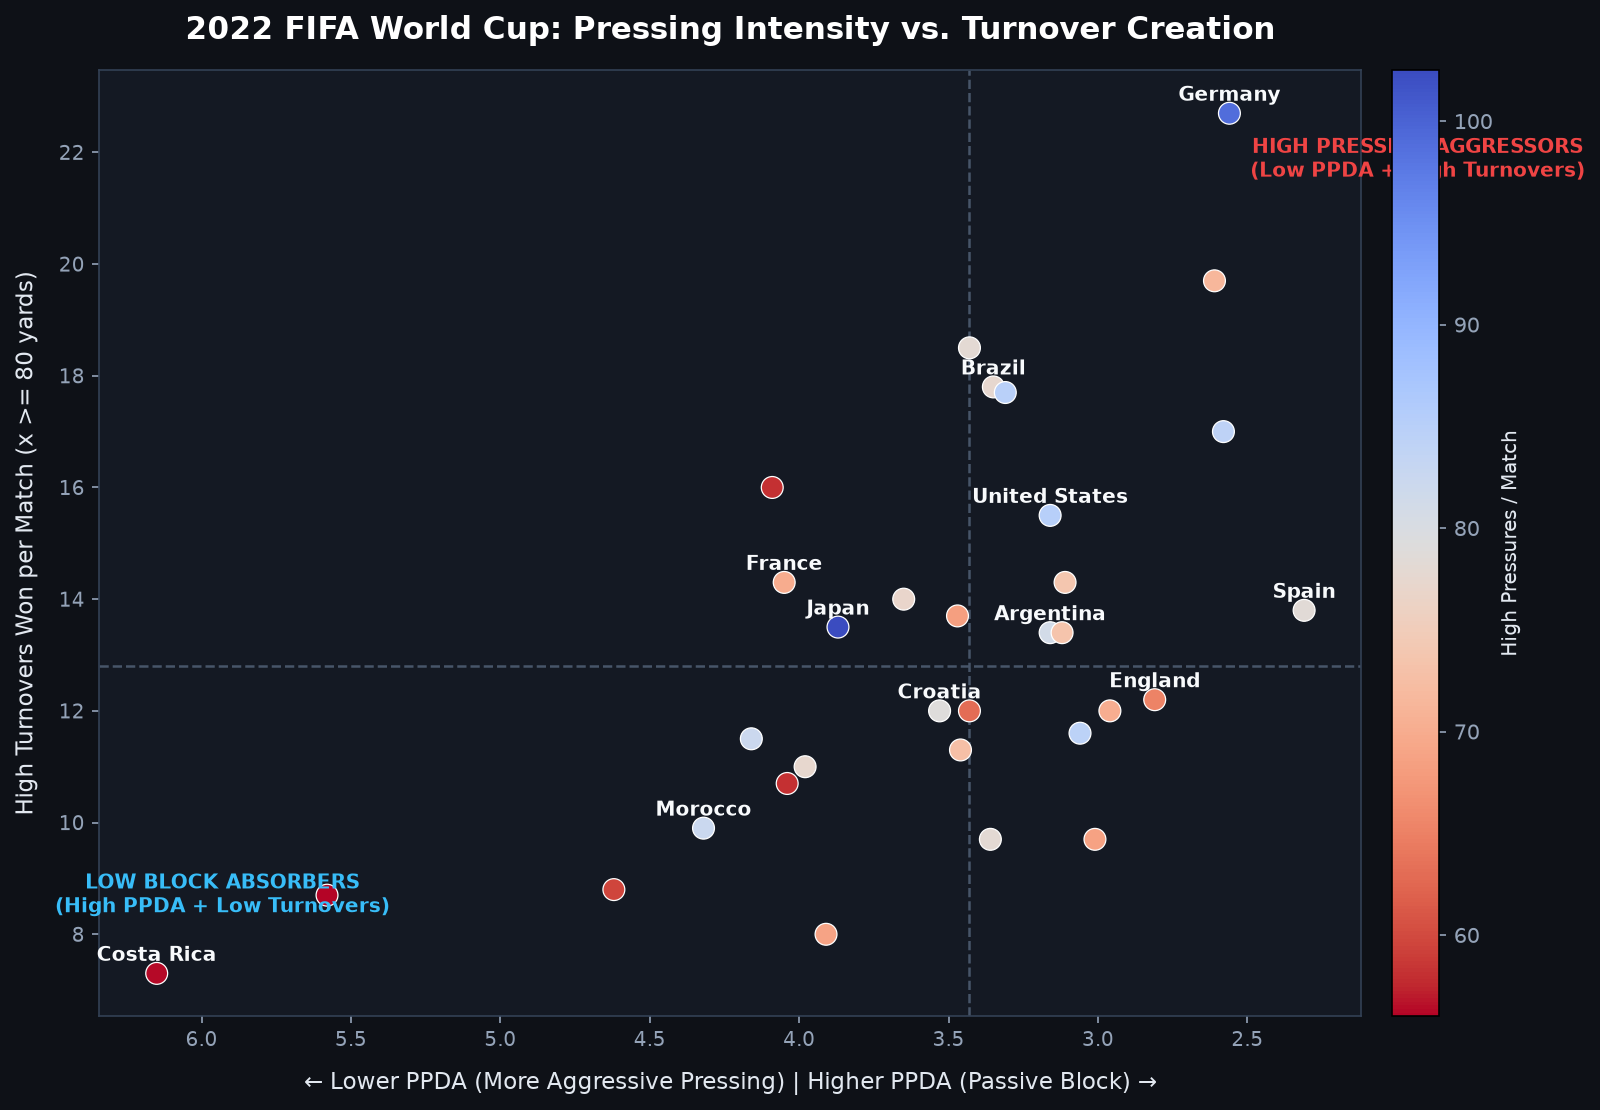

In [22]:
# Tactical Quadrant Scatter Plot: PPDA vs High Turnovers per match
fig, ax = plt.subplots(figsize=(11, 7.5), facecolor='#0e1117')
ax.set_facecolor('#141923')

x_vals = team_pressing_summary['mean_ppda']
y_vals = team_pressing_summary['high_turnovers_per_match']

median_x = x_vals.median()
median_y = y_vals.median()

# Draw quadrant threshold medians
ax.axvline(median_x, color='#475569', linestyle='--', linewidth=1.2, zorder=1)
ax.axhline(median_y, color='#475569', linestyle='--', linewidth=1.2, zorder=1)

# Scatter points
scatter = ax.scatter(
    x_vals, y_vals,
    c=team_pressing_summary['high_pressures_per_match'],
    cmap='coolwarm_r',
    s=110,
    edgecolors='#ffffff',
    linewidth=0.6,
    zorder=3
)

# Add labels for key national teams
highlight_teams = [
    'Spain', 'Germany', 'Argentina', 'France', 'Croatia',
    'Morocco', 'Costa Rica', 'Japan', 'Brazil', 'England', 'United States'
]
for _, row in team_pressing_summary.iterrows():
    team_name = row['team']
    if team_name in highlight_teams:
        ax.annotate(
            team_name,
            (row['mean_ppda'], row['high_turnovers_per_match']),
            xytext=(0, 6),
            textcoords="offset points",
            fontsize=9.5,
            weight='bold',
            color='#f8fafc',
            ha='center',
            zorder=4
        )

# Invert X-axis so lower PPDA (more intense pressing) is positioned to the right
ax.invert_xaxis()

# Labels and title
ax.set_xlabel("← Lower PPDA (More Aggressive Pressing) | Higher PPDA (Passive Block) →", color='#e2e8f0', fontsize=11, labelpad=10)
ax.set_ylabel("High Turnovers Won per Match (x >= 80 yards)", color='#e2e8f0', fontsize=11, labelpad=10)

ax.tick_params(colors='#94a3b8', labelsize=9.5)
for spine in ax.spines.values():
    spine.set_color('#334155')

# Quadrant Annotations
ax.text(median_x - 1.5, y_vals.max() * 0.95, "HIGH PRESSING AGGRESSORS\n(Low PPDA + High Turnovers)", color='#ef4444', fontsize=9.5, weight='bold', ha='center')
ax.text(median_x + 2.5, y_vals.min() * 1.15, "LOW BLOCK ABSORBERS\n(High PPDA + Low Turnovers)", color='#38bdf8', fontsize=9.5, weight='bold', ha='center')

plt.title("2022 FIFA World Cup: Pressing Intensity vs. Turnover Creation", color='#ffffff', fontsize=15, weight='bold', pad=15)

# Colorbar
cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label("High Pressures / Match", color='#e2e8f0', fontsize=9.5)
cbar.ax.yaxis.set_tick_params(color='#94a3b8')
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='#94a3b8')

plt.tight_layout()
plt.show()


### 7. Day 24 Analytical Takeaways & Portfolio Summary

1. **Decoupling Volume from Intensity**: Raw count of defensive actions is heavily distorted by match possession share. PPDA neutralizes this confounding effect by standardizing against opponent build-up volume.
2. **Spain's Territorial Strangulation**: Spain posted the tournament's lowest PPDA ($2.31$ against Costa Rica, maintaining sub-$8.0$ across the group stage), confirming Luis Enrique's extreme commitment to counter-pressing in the initial phase.
3. **High Turnover Conversion**: Teams in the upper-right quadrant (Low PPDA + High Turnovers) generated immediate transition shots from ball recoveries inside the opponent's final 40 yards.
4. **Morocco's Low-Block Resilience**: Morocco recorded high PPDA values, demonstrating that passive defensive blocks are not tactical failures, but disciplined defensive strategies designed to absorb pressure and strike on long-distance counters.
